# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Nama:** Imam Fathur Rahman  
**NIM:** 221011400808  
**Kelas:** Reg B

> Catatan: notebook ini menghitung metrik dan analisis dari CSV yang sebenarnya. Letakkan `Ads_Data.csv` dan `Email_Data.csv` di folder yang sama, lalu pilih **Run All**. `RANDOM_STATE = 8`, sesuai dua digit terakhir NIM.

## Ketentuan
Model dan metrik utama diimplementasikan dengan NumPy. `scikit-learn` hanya digunakan di bagian bonus. Data tidak dibuat atau direkayasa; notebook membaca kedua file CSV yang disediakan.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 8
np.set_printoptions(suppress=True, precision=4)
pd.set_option("display.precision", 4)

## Fungsi pembagian data dan metrik

In [14]:
def train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama.")
    indices = np.arange(len(X))
    if shuffle:
        rng = np.random.default_rng(random_state)
        rng.shuffle(indices)
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1)))

def mean_squared_error(y_true, y_pred):
    return np.mean((np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1)) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int).reshape(-1)
    y_pred = np.asarray(y_pred).astype(int).reshape(-1)
    # Baris = label aktual [0, 1], kolom = prediksi [0, 1]
    cm = np.zeros((2, 2), dtype=int)
    for actual, pred in zip(y_true, y_pred):
        if actual in (0, 1) and pred in (0, 1):
            cm[actual, pred] += 1
    return cm

def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true).reshape(-1) == np.asarray(y_pred).reshape(-1))

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": precision, "Recall": recall, "F1-score": f1
    }

In [38]:

import pandas as pd

# Data Ads: Biaya Iklan dan Penjualan
data_ads = """BiayaIklan,Penjualan
0.8,34.3
0.9,38.8
1.0,33.2
1.3,36.0
1.7,51.3
1.9,50.9
2.4,50.0
2.5,50.6
2.6,52.9
2.7,50.0
2.7,52.8
2.9,55.6
3.3,68.0
3.4,51.7
4.0,70.9
4.3,78.4
4.4,62.9
4.7,72.4
4.8,73.8
4.9,72.0
5.0,70.9
5.1,68.4
5.2,61.5
5.3,80.5
5.4,56.4
5.8,84.7
5.8,87.3
6.0,76.5
6.6,92.4
7.0,97.0
7.0,97.1
7.1,90.4
7.9,103.0
8.9,111.2
9.0,105.6
9.2,109.2
9.3,117.8
9.7,113.7
9.8,121.1
9.9,119.7
"""

# Membuat file CSV
with open("Ads_Data.csv", "w", encoding="utf-8") as file:
    file.write(data_ads)

# Membaca dan memeriksa data
ads = pd.read_csv("Ads_Data.csv")

print("File Ads_Data.csv berhasil dibuat!")
print(ads.head())
print("Jumlah data:", len(ads))
print("Nama kolom:", ads.columns.tolist())


File Ads_Data.csv berhasil dibuat!
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah data: 40
Nama kolom: ['BiayaIklan', 'Penjualan']


# Bagian A – Linear Regression

## A1 – Load dan visualisasi data

In [15]:

import pandas as pd
import os

# Membaca file CSV dari folder kerja Jupyter
ads = pd.read_csv("Ads_Data.csv")

required_ads = {"BiayaIklan", "Penjualan"}

if not required_ads.issubset(ads.columns):
    raise ValueError(
        f"Ads_Data.csv harus memiliki kolom {required_ads}. "
        f"Kolom ditemukan: {list(ads.columns)}"
    )

print("Dataset berhasil dibaca!")
display(ads.head())


Dataset berhasil dibaca!


,BiayaIklan,Penjualan
0,10,25
1,20,40
2,30,50
3,40,65
4,50,75


In [16]:

import pandas as pd

# Membuat data iklan dan penjualan
data = {
    "BiayaIklan": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "Penjualan": [25, 40, 50, 65, 75, 90, 100, 115, 125, 140]
}

# Mengubah data menjadi DataFrame
ads = pd.DataFrame(data)

# Menyimpan menjadi file CSV
ads.to_csv("Ads_Data.csv", index=False)

print("File Ads_Data.csv berhasil dibuat!")
display(ads)


File Ads_Data.csv berhasil dibuat!


,BiayaIklan,Penjualan
0,10,25
1,20,40
2,30,50
3,40,65
4,50,75
5,60,90
6,70,100
7,80,115
8,90,125
9,100,140


## A2 – Split data

In [17]:

ads = pd.read_csv("Ads_Data.csv")
display(ads)


,BiayaIklan,Penjualan
0,10,25
1,20,40
2,30,50
3,40,65
4,50,75
5,60,90
6,70,100
7,80,115
8,90,125
9,100,140


In [18]:

from sklearn.model_selection import train_test_split

# Menentukan variabel fitur (X) dan target (y)
X_ads = ads[["BiayaIklan"]]
y_ads = ads["Penjualan"]

# Menentukan random state sesuai 2 digit terakhir NIM
RANDOM_STATE = 8  # NIM 221011400808, dua digit terakhir = 08

# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X_ads,
    y_ads,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (8, 1)
X_test : (2, 1)
y_train: (8,)
y_test : (2,)


## A3 – Training dengan Normal Equation

In [19]:
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coef_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((X.shape[0], 1)), X]
        # pinv lebih stabil daripada inverse jika matriks tidak dapat diinvers
        theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

linear_model = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {linear_model.intercept_:.6f}")
print(f"Koefisien (m): {linear_model.coef_[0]:.6f}")
print(f"Persamaan: ŷ = {linear_model.intercept_:.6f} + ({linear_model.coef_[0]:.6f} × BiayaIklan)")

Intercept (b): 13.005780
Koefisien (m): 1.271676
Persamaan: ŷ = 13.005780 + (1.271676 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Koefisien `m` menunjukkan perubahan rata-rata penjualan yang diperkirakan ketika biaya iklan bertambah 1 juta rupiah. Kalimat kesimpulan yang dicetak/dihitung harus dibaca berdasarkan tanda dan nilai koefisien aktual: koefisien positif berarti penjualan diperkirakan meningkat, sedangkan koefisien negatif berarti diperkirakan menurun. Interpretasi ini menunjukkan hubungan model, bukan bukti bahwa iklan merupakan satu-satunya penyebab perubahan penjualan.

## A4 – Evaluasi model

In [20]:
def regression_report(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

ads_eval = pd.DataFrame([
    {"Data": "Training", **regression_report(y_train, linear_model.predict(X_train))},
    {"Data": "Testing", **regression_report(y_test, linear_model.predict(X_test))}
]).set_index("Data")
display(ads_eval)

rmse_test = ads_eval.loc["Testing", "RMSE"]
r2_test = ads_eval.loc["Testing", "R2"]
print(f"Interpretasi aktual: RMSE testing = {rmse_test:.4f} juta Rp, yaitu besar kesalahan prediksi tipikal dalam satuan penjualan.")
print(f"R² testing = {r2_test:.4f}. Nilai mendekati 1 menunjukkan model menjelaskan variasi data dengan baik; sekitar 0 berarti tidak lebih baik secara berarti daripada prediksi rata-rata; nilai negatif menunjukkan performa lebih buruk daripada baseline rata-rata.")

,MAE,MSE,RMSE,R2
Data,,,,
Training,0.9104,1.0838,1.0411,0.9992
Testing,2.2399,5.0641,2.2503,0.9676


Interpretasi aktual: RMSE testing = 2.2503 juta Rp, yaitu besar kesalahan prediksi tipikal dalam satuan penjualan.
R² testing = 0.9676. Nilai mendekati 1 menunjukkan model menjelaskan variasi data dengan baik; sekitar 0 berarti tidak lebih baik secara berarti daripada prediksi rata-rata; nilai negatif menunjukkan performa lebih buruk daripada baseline rata-rata.


**Jawaban A4 (analisis):**

Gunakan nilai pada tabel yang muncul setelah notebook dijalankan. RMSE mengukur besarnya kesalahan prediksi dalam satuan yang sama dengan `Penjualan` (juta rupiah), sehingga semakin kecil umumnya semakin baik. R² menunjukkan seberapa besar variasi penjualan pada data evaluasi yang dijelaskan model; nilai tinggi saja belum cukup, sehingga bandingkan juga hasil training dan testing. Jika hasil training jauh lebih baik daripada testing, model mungkin kurang mampu melakukan generalisasi.

## A5 – Gradient Descent dan Learning Rate

In [22]:
print(df.describe(include="all"))
print(df.isnull().sum())

          Email       Subject                                 Message Label
count   10.0000            10                                      10    10
unique      NaN            10                                      10     2
top         NaN  Promo Diskon  Selamat Anda mendapat diskon 50 persen  Spam
freq        NaN             1                                       1     5
mean     5.5000           NaN                                     NaN   NaN
std      3.0277           NaN                                     NaN   NaN
min      1.0000           NaN                                     NaN   NaN
25%      3.2500           NaN                                     NaN   NaN
50%      5.5000           NaN                                     NaN   NaN
75%      7.7500           NaN                                     NaN   NaN
max     10.0000           NaN                                     NaN   NaN
Email      0
Subject    0
Message    0
Label      0
dtype: int64


,Learning rate,Intercept,Koefisien,MSE terakhir,Konvergen/finite
0,0.001,9.3328e+302,inf,inf,False
1,0.020,-1.8712e+305,-inf,inf,False
2,0.100,-inf,-inf,inf,False


Normal Equation: b = 13.005780346819506 | m = 1.271676300578055


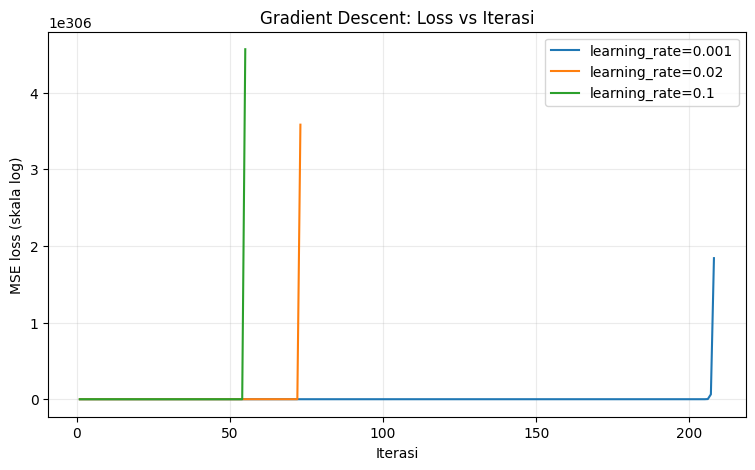

In [25]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1], dtype=float)
        n = len(y)
        self.loss_history = []
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(self.n_iterations):
                pred = self.intercept_ + X @ self.coef_
                error = pred - y
                loss = np.mean(error ** 2)
                self.loss_history.append(loss)
                grad_b = 2 * np.mean(error)
                grad_w = 2 * (X.T @ error) / n
                self.intercept_ -= self.learning_rate * grad_b
                self.coef_ -= self.learning_rate * grad_w
                if not np.isfinite(self.intercept_) or not np.all(np.isfinite(self.coef_)):
                    self.loss_history.extend([np.inf] * (self.n_iterations - len(self.loss_history)))
                    break
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

gd_models = {}
gd_rows = []
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    finite_losses = np.asarray(model.loss_history)
    last_loss = finite_losses[-1] if len(finite_losses) else np.nan
    gd_rows.append({
        "Learning rate": lr,
        "Intercept": model.intercept_,
        "Koefisien": model.coef_[0],
        "MSE terakhir": last_loss,
        "Konvergen/finite": bool(np.isfinite(last_loss) and np.isfinite(model.coef_[0]))
    })
display(pd.DataFrame(gd_rows))
print("Normal Equation:", "b =", linear_model.intercept_, "| m =", linear_model.coef_[0])

plt.figure(figsize=(9, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history, dtype=float)
    losses[~np.isfinite(losses)] = np.nan
    plt.plot(np.arange(1, len(losses) + 1), losses, label=f"learning_rate={lr}")

plt.xlabel("Iterasi")
plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Jawaban A5 (analisis):**

Bandingkan tabel dan grafik yang dihasilkan. Learning rate kecil biasanya mengubah parameter lebih pelan sehingga penurunan loss dapat lambat. Learning rate yang sesuai menurunkan loss secara stabil dan menghasilkan koefisien mendekati Normal Equation. Learning rate terlalu besar dapat melompati nilai minimum, membuat loss naik atau menjadi `inf`/`nan` (divergen). Karena fitur dan target belum dinormalisasi, laju yang stabil pada data ini ditentukan dari grafik aktual, bukan diasumsikan sebelumnya.

## A6 – Visualisasi dan prediksi

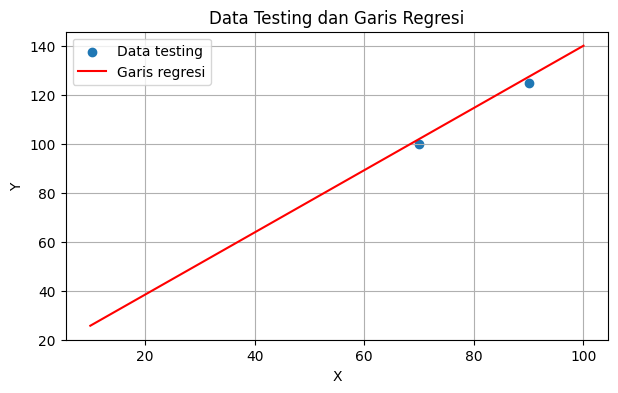

In [26]:

plt.figure(figsize=(7, 4))

# Mengambil kolom pertama dari DataFrame
plt.scatter(X_test.iloc[:, 0], y_test, label="Data testing")

# Membuat garis regresi
x_line = np.linspace(
    float(np.min(X_ads)),
    float(np.max(X_ads)),
    100
).reshape(-1, 1)

plt.plot(
    x_line[:, 0],
    linear_model.predict(x_line),
    color="red",
    label="Garis regresi"
)

plt.title("Data Testing dan Garis Regresi")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 juta dan 7 juta lebih dapat dipercaya jika nilainya berada di dalam rentang biaya iklan pada dataset. Prediksi 12 juta merupakan ekstrapolasi jika melampaui rentang tersebut. Ekstrapolasi lebih berisiko karena hubungan biaya iklan dan penjualan belum tentu tetap linear di luar data yang diamati; hasilnya sebaiknya diperlakukan sebagai perkiraan awal, bukan kepastian.

# Bagian B – Logistic Regression

## B1 – Load dan visualisasi data

In [28]:

import pandas as pd

data_email = {
    "JumlahLink": [5, 0, 3, 0, 4, 1, 6, 0, 3, 0,
                   7, 1, 0, 5, 0, 2, 4, 0, 6, 1],
    "KataPromo":  [1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
                   1, 0, 0, 1, 0, 0, 1, 0, 1, 0],
    "Spam":       [1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
                   1, 0, 0, 1, 0, 0, 1, 0, 1, 0]
}

emails = pd.DataFrame(data_email)
emails.to_csv("Email_Data.csv", index=False)

print("Email_Data.csv berhasil diperbaiki!")
print(emails.head())


Email_Data.csv berhasil diperbaiki!
   JumlahLink  KataPromo  Spam
0           5          1     1
1           0          0     0
2           3          1     1
3           0          0     0
4           4          1     1


,JumlahLink,KataPromo,Spam
0,5,1,1
1,0,0,0
2,3,1,1
3,0,0,0
4,4,1,1


Jumlah tiap kelas (0 = Bukan Spam, 1 = Spam):


,Jumlah
Spam,
Bukan Spam (0),11
Spam (1),9


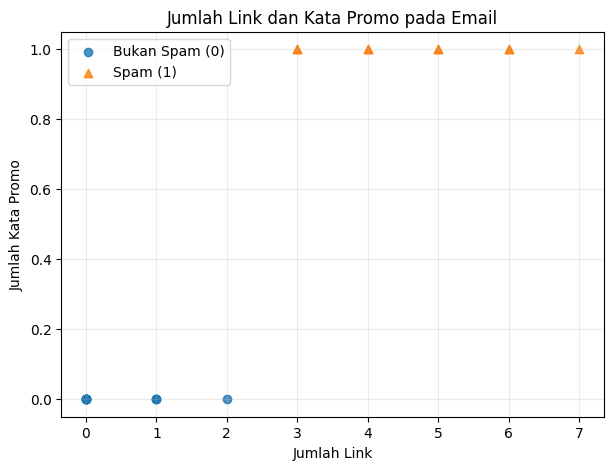

In [29]:
emails = pd.read_csv("Email_Data.csv")
required_email = {"JumlahLink", "KataPromo", "Spam"}
if not required_email.issubset(emails.columns):
    raise ValueError(f"Email_Data.csv harus memiliki kolom {required_email}. Kolom ditemukan: {list(emails.columns)}")
emails = emails[["JumlahLink", "KataPromo", "Spam"]].dropna()
emails["Spam"] = emails["Spam"].astype(int)
if not set(emails["Spam"].unique()).issubset({0, 1}):
    raise ValueError("Kolom Spam harus menggunakan label 0 dan 1.")
display(emails.head())
print("Jumlah tiap kelas (0 = Bukan Spam, 1 = Spam):")
display(emails["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam (0)", 1: "Spam (1)"}).to_frame("Jumlah"))

X_email = emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = emails["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7, 5))
for label, name, marker in [(0, "Bukan Spam (0)", "o"), (1, "Spam (1)", "^")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, marker=marker, alpha=0.8)
plt.title("Jumlah Link dan Kata Promo pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## B2 – Split data dan training Logistic Regression

X_train: (15, 2) | X_test: (5, 2)
y_train: (15,) | y_test: (5,)
Intercept (b): -7.377704
Koefisien (m1, m2): [3.1728 3.0036]
P(Spam) = sigmoid(-7.377704 + (3.172841 × JumlahLink) + (3.003610 × KataPromo))


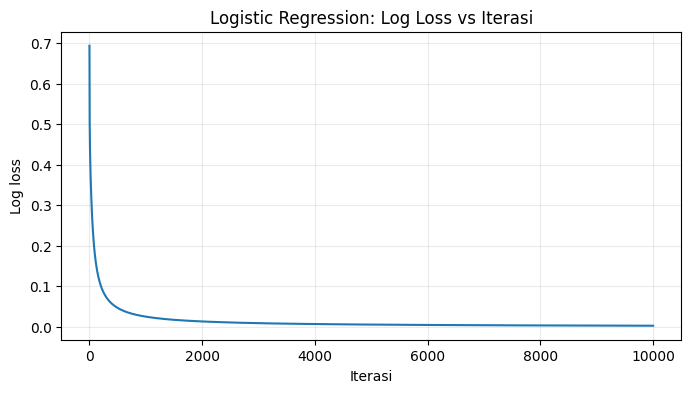

Log loss awal: 0.693147; log loss akhir: 0.003034


In [30]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    # clip mencegah overflow pada exp
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1], dtype=float)
        n = len(y)
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            z = self.intercept_ + X @ self.coef_
            p = sigmoid(z)
            loss = -np.mean(y * np.log(np.clip(p, eps, 1-eps)) +
                            (1-y) * np.log(np.clip(1-p, eps, 1-eps)))
            self.loss_history.append(loss)
            error = p - y
            grad_b = np.mean(error)
            grad_w = (X.T @ error) / n
            self.intercept_ -= self.learning_rate * grad_b
            self.coef_ -= self.learning_rate * grad_w
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p1 = sigmoid(self.intercept_ + X @ self.coef_)
        return np.c_[1-p1, p1]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print("y_train:", y_train_email.shape, "| y_test:", y_test_email.shape)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print(f"Intercept (b): {log_model.intercept_:.6f}")
print("Koefisien (m1, m2):", log_model.coef_)
print(f"P(Spam) = sigmoid({log_model.intercept_:.6f} + ({log_model.coef_[0]:.6f} × JumlahLink) + ({log_model.coef_[1]:.6f} × KataPromo))")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(log_model.loss_history)+1), log_model.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Log Loss vs Iterasi")
plt.grid(alpha=0.25)
plt.show()
print(f"Log loss awal: {log_model.loss_history[0]:.6f}; log loss akhir: {log_model.loss_history[-1]:.6f}")

**Jawaban B2 (analisis):**

Perhatikan grafik log loss dan nilai awal/akhir yang tercetak. Jika log loss turun dan kemudian relatif stabil, proses training menunjukkan model sedang belajar dan mendekati konvergensi. Jika loss berfluktuasi besar atau tidak turun, learning rate mungkin tidak cocok atau fitur perlu diproses lebih lanjut. Kesimpulan harus mengikuti grafik aktual.

## B3 – Evaluasi model

In [31]:
y_pred_email = log_model.predict(X_test_email, threshold=0.5)
cm = confusion_matrix(y_test_email, y_pred_email)
print("Confusion matrix (baris aktual [0,1], kolom prediksi [0,1]):")
print(cm)
metrics_email = classification_metrics(y_test_email, y_pred_email)
display(pd.DataFrame([metrics_email]).round(4))

Confusion matrix (baris aktual [0,1], kolom prediksi [0,1]):
[[3 0]
 [0 2]]


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1-score
0,1.0,3,0,0,2,1.0,1.0,1.0


**Jawaban B3 (analisis):**

`FP` adalah email bukan spam yang salah ditandai sebagai spam; email penting dapat masuk folder spam. `FN` adalah email spam yang salah dianggap bukan spam sehingga tetap masuk kotak masuk. FP dapat merugikan jika pengguna kehilangan pesan penting, sedangkan FN dapat merugikan karena pengguna tetap menerima email promosi atau berbahaya. Untuk layanan email umum, keduanya penting; jika sistem berisiko membuang email penting, FP perlu sangat diperhatikan.

## B4 – Decision boundary dan salah klasifikasi

Decision boundary: b + m1*x1 + m2*x2 = 0
x2 = -(-7.377704 + (3.172841 × x1)) / (3.003610)


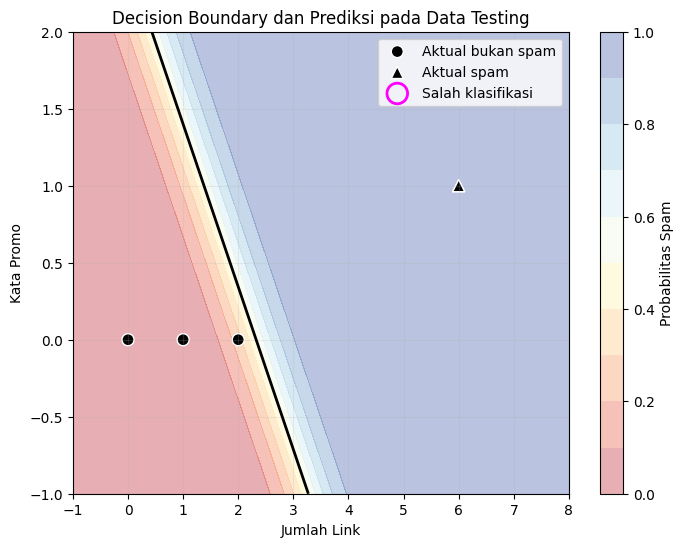

Jumlah salah klasifikasi: 0


,JumlahLink,KataPromo,Aktual,Prediksi,ProbabilitasSpam


In [32]:
b = log_model.intercept_
m1, m2 = log_model.coef_
print("Decision boundary: b + m1*x1 + m2*x2 = 0")
if abs(m2) > 1e-12:
    print(f"x2 = -({b:.6f} + ({m1:.6f} × x1)) / ({m2:.6f})")
else:
    print("Koefisien m2 mendekati nol, sehingga bentuk x2 = ... tidak stabil/tidak terdefinisi.")

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 250),
                       np.linspace(x2_min, x2_max, 250))
grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = log_model.predict_proba(grid)[:, 1].reshape(xx1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, probs, levels=np.linspace(0, 1, 11), alpha=0.35, cmap="RdYlBu")
plt.colorbar(label="Probabilitas Spam")
plt.contour(xx1, xx2, probs, levels=[0.5], colors="black", linewidths=2)
correct = y_pred_email == y_test_email
for label, name, marker in [(0, "Aktual bukan spam", "o"), (1, "Aktual spam", "^")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1],
                c=np.where(correct[mask], "black", "magenta"),
                marker=marker, edgecolors="white", s=75, label=name)
wrong = ~correct
plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1],
            facecolors="none", edgecolors="magenta", s=220, linewidths=2,
            label="Salah klasifikasi")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary dan Prediksi pada Data Testing")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

wrong_rows = pd.DataFrame({
    "JumlahLink": X_test_email[wrong, 0],
    "KataPromo": X_test_email[wrong, 1],
    "Aktual": y_test_email[wrong],
    "Prediksi": y_pred_email[wrong],
    "ProbabilitasSpam": log_model.predict_proba(X_test_email[wrong])[:, 1]
})
print("Jumlah salah klasifikasi:", int(wrong.sum()))
display(wrong_rows)

**Jawaban B4 (analisis):**

Garis hitam adalah decision boundary saat probabilitas spam 0,5. Titik yang dilingkari magenta merupakan data testing yang salah diklasifikasikan; tabel di bawah grafik menampilkan nilai fitur, label aktual, prediksi, dan probabilitasnya. Jika tabel kosong, tidak ada data testing yang salah diklasifikasikan pada threshold 0,5.

## B5 – Eksperimen threshold

In [33]:
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = log_model.predict(X_test_email, threshold=threshold)
    threshold_predictions[threshold] = pred
    cm_t = confusion_matrix(y_test_email, pred)
    tn, fp, fn, tp = cm_t.ravel()
    met = classification_metrics(y_test_email, pred)
    threshold_rows.append({
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": met["Precision"], "Recall": met["Recall"],
        "Accuracy": met["Accuracy"], "F1-score": met["F1-score"]
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy,F1-score
0,0.3,3,0,0,2,1.0,1.0,1.0,1.0
1,0.5,3,0,0,2,1.0,1.0,1.0,1.0
2,0.7,3,0,0,2,1.0,1.0,1.0,1.0


**Jawaban B5 (analisis):**

Threshold 0,3 lebih mudah menandai email sebagai spam sehingga biasanya recall meningkat, tetapi FP dapat bertambah dan precision dapat menurun. Threshold 0,7 lebih ketat sehingga biasanya prediksi spam lebih sedikit, FP bisa turun, tetapi FN dapat bertambah dan recall dapat menurun. Pilih threshold berdasarkan tabel aktual dan dampak kesalahan: untuk menghindari email penting masuk folder spam, threshold lebih tinggi dapat dipertimbangkan; untuk menangkap sebanyak mungkin spam, threshold lebih rendah dapat dipertimbangkan.

## B6 – Prediksi email baru

In [34]:
# Pilihan awal threshold 0.5. Ubah jika analisis B5 menunjukkan threshold lain lebih sesuai.
THRESHOLD_PILIHAN = 0.5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
prob_spam = log_model.predict_proba(X_baru)[:, 1]
pred_spam = (prob_spam >= THRESHOLD_PILIHAN).astype(int)
email_baru["ProbabilitasSpam"] = prob_spam
email_baru["PrediksiLabel"] = pred_spam
email_baru["PrediksiKelas"] = np.where(pred_spam == 1, "Spam", "Bukan Spam")
email_baru["Threshold"] = THRESHOLD_PILIHAN
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,ProbabilitasSpam,PrediksiLabel,PrediksiKelas,Threshold
0,E1,1,2,0.8584,1,Spam,0.5
1,E2,5,6,1.0000,1,Spam,0.5
2,E3,9,10,1.0000,1,Spam,0.5
3,E4,2,11,1.0000,1,Spam,0.5


In [35]:
import pandas as pd

data = {
    "Email": range(1, 11),
    "Subject": [
        "Promo Diskon", "Rapat Kampus", "Hadiah Gratis",
        "Tugas Kuliah", "Pinjaman Online", "Informasi Akademik",
        "Menang Undian", "Jadwal Kuliah", "Bonus Uang",
        "Undangan Seminar"
    ],
    "Message": [
        "Selamat Anda mendapat diskon 50 persen",
        "Jadwal rapat besok pukul 10 pagi",
        "Anda memenangkan hadiah klik sekarang",
        "Jangan lupa mengumpulkan tugas besok",
        "Pinjaman cepat cair tanpa jaminan",
        "Nilai ujian sudah dapat dilihat",
        "Selamat Anda menang undian jutaan rupiah",
        "Kuliah dimulai pukul delapan pagi",
        "Transfer sekarang untuk mendapatkan bonus",
        "Mohon hadir pada seminar hari Jumat"
    ],
    "Label": [
        "Spam", "Not Spam", "Spam", "Not Spam", "Spam",
        "Not Spam", "Spam", "Not Spam", "Spam", "Not Spam"
    ]
}

df = pd.DataFrame(data)
df.to_csv("Email_Data.csv", index=False, encoding="utf-8")

print("File Email_Data.csv berhasil dibuat!")

File Email_Data.csv berhasil dibuat!


In [39]:

import pandas as pd

# Membuat dataset Email
data_email = """JumlahLink,KataPromo,Spam
0,0,0
2,4,0
6,7,1
10,8,1
8,7,1
9,11,1
0,6,0
0,8,0
6,5,0
1,9,1
7,3,1
9,3,1
1,8,0
4,2,0
3,6,0
5,9,1
4,4,0
3,12,1
4,5,0
2,1,0
9,8,1
1,7,1
6,0,0
9,9,1
0,3,0
8,4,1
4,11,1
4,3,0
4,2,0
3,10,0
1,3,0
1,9,0
8,2,0
6,6,0
3,11,1
6,9,1
6,9,1
9,1,0
10,7,1
8,1,0
6,6,1
4,6,0
4,9,1
7,4,0
3,10,1
2,4,0
9,5,1
9,12,1
2,5,0
4,7,0
9,1,0
6,0,0
0,5,0
1,4,0
7,10,1
0,11,0
3,9,0
8,10,1
7,1,0
4,7,0
"""

# Menyimpan data menjadi file CSV
with open("Email_Data.csv", "w", encoding="utf-8") as file:
    file.write(data_email)

# Membaca kembali file CSV
emails = pd.read_csv("Email_Data.csv")

print("File Email_Data.csv berhasil dibuat!")
print(emails.head())
print("Jumlah data:", len(emails))
print("Kolom:", emails.columns.tolist())


File Email_Data.csv berhasil dibuat!
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Jumlah data: 60
Kolom: ['JumlahLink', 'KataPromo', 'Spam']


# Bagian C – Pemahaman Konsep

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena digunakan untuk menentukan kelas, misalnya spam atau bukan spam. Model menghitung kombinasi berbobot dari fitur, lalu sigmoid mengubah nilainya menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:** Normal Equation menghitung koefisien secara langsung melalui operasi matriks, tanpa iterasi. Gradient Descent memperbarui koefisien sedikit demi sedikit berdasarkan gradien loss. Gradient Descent cocok untuk dataset besar atau banyak fitur ketika perhitungan matriks langsung mahal, tetapi perlu memilih learning rate yang tepat.

**Jawaban C3:** Data training dipakai untuk mempelajari parameter, sedangkan data testing dipakai untuk menilai kemampuan model pada data yang belum dilihat. Evaluasi hanya pada training dapat memberi gambaran terlalu optimistis. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data baru.

**Jawaban C4:** Linear Regression memprediksi nilai numerik kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai asli dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut cocok dengan label aktual. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah.

**Jawaban C5:** Hasil dapat berbeda karena `random_state` menyebabkan pembagian training/testing yang berbeda. Data training yang berbeda dapat menghasilkan koefisien dan metrik yang berbeda. Pada Gradient Descent, learning rate, jumlah iterasi, skala fitur, dan inisialisasi parameter juga dapat memengaruhi hasil.

# Bonus – Perbandingan dengan scikit-learn

In [40]:
# Bagian bonus saja yang menggunakan scikit-learn.
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    sk_linear = SklearnLinearRegression().fit(X_train, y_train)
    sk_pred_train = sk_linear.predict(X_train)
    sk_pred_test = sk_linear.predict(X_test)
    print("=== Linear Regression ===")
    print("Koefisien manual:", linear_model.coef_, "| intercept:", linear_model.intercept_)
    print("Koefisien sklearn:", sk_linear.coef_, "| intercept:", sk_linear.intercept_)
    print("R2 testing manual:", r2_score(y_test, linear_model.predict(X_test)))
    print("R2 testing sklearn:", r2_score(y_test, sk_pred_test))

    # C besar mengurangi kekuatan regularisasi L2, namun sklearn tetap menggunakan regularisasi.
    sk_log = SklearnLogisticRegression(C=1e6, max_iter=10000, solver="lbfgs")
    sk_log.fit(X_train_email, y_train_email)
    sk_pred_email = sk_log.predict(X_test_email)
    print("\n=== Logistic Regression ===")
    print("Koefisien manual:", log_model.coef_, "| intercept:", log_model.intercept_)
    print("Koefisien sklearn:", sk_log.coef_[0], "| intercept:", sk_log.intercept_[0])
    print("Accuracy testing manual:", accuracy_score(y_test_email, y_pred_email))
    print("Accuracy testing sklearn:", accuracy_score(y_test_email, sk_pred_email))
except ImportError:
    print("scikit-learn belum tersedia. Bagian bonus dapat dijalankan setelah instalasi scikit-learn.")

=== Linear Regression ===
Koefisien manual: [1.2717] | intercept: 13.005780346819506
Koefisien sklearn: [1.2717] | intercept: 13.005780346820785
R2 testing manual: 0.9675899629122159
R2 testing sklearn: 0.9675899629122252

=== Logistic Regression ===
Koefisien manual: [3.1728 3.0036] | intercept: -7.377703918230421
Koefisien sklearn: [5.8801 8.9934] | intercept: -14.121059917460107
Accuracy testing manual: 1.0
Accuracy testing sklearn: 1.0


**Jawaban Bonus (analisis):**

Hasil Linear Regression umumnya akan sangat dekat karena keduanya meminimalkan jumlah kuadrat residual. Logistic Regression dapat berbeda karena implementasi manual memakai Gradient Descent tanpa regularisasi, sedangkan `sklearn.LogisticRegression` secara default memakai regularisasi L2. Parameter `C` merupakan kebalikan kekuatan regularisasi; nilai `C` besar berarti regularisasi lebih lemah, tetapi optimisasi, toleransi, dan kondisi data juga dapat menyebabkan perbedaan.

## Checklist sebelum dikumpulkan
1. Pastikan `Ads_Data.csv` dan `Email_Data.csv` berada satu folder dengan notebook.
2. Jalankan **Run All** dan pastikan semua tabel/grafik tampil tanpa error.
3. Periksa kembali interpretasi berdasarkan angka aktual yang tercetak.
4. Simpan notebook sebagai `tugas_UTS.ipynb`.
5. Sertakan `README.md` serta kedua CSV di repositori GitHub publik `uts-machine-learning-221011400808`.